In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

ModuleNotFoundError: No module named 'matplotlib'

In [2]:
%pip install matplotlib


  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp313-cp313-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp313-cp313-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl (70 kB)
Using cached pillow-13.0.0-cp313-cp313-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
All Libraries Imported Successfully!


In [4]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


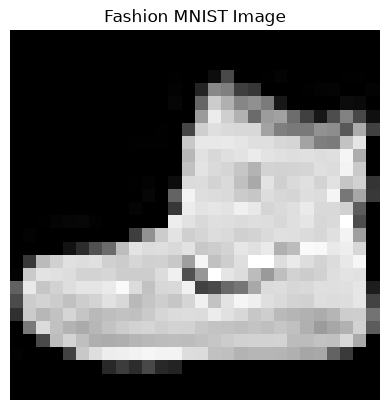

In [5]:
plt.imshow(x_train[0], cmap="gray")

plt.title("Fashion MNIST Image")
plt.axis("off")

plt.show()

In [7]:
# Normalize image values between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

print("Image Classification Training Completed!")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 23ms/step - accuracy: 0.8140 - loss: 0.5222 - val_accuracy: 0.8582 - val_loss: 0.3878
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8737 - loss: 0.3491 - val_accuracy: 0.8817 - val_loss: 0.3283
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8895 - loss: 0.3031 - val_accuracy: 0.8942 - val_loss: 0.2966
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.9014 - loss: 0.2705 - val_accuracy: 0.8978 - val_loss: 0.2762
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.9110 - loss: 0.2459 - val_accuracy: 0.9072 - val_loss: 0.2603
Image Classification Training Completed!


In [10]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8964 - loss: 0.2790
Test Loss: 0.2790406048297882
Test Accuracy: 89.6399974822998 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step


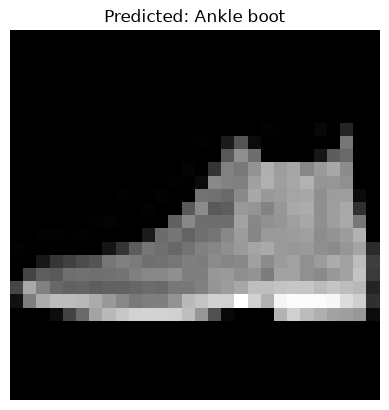

Predicted Class: Ankle boot
Actual Class: Ankle boot


In [11]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

prediction = model.predict(x_test[:1])

predicted_class = np.argmax(prediction[0])

plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.title("Predicted: " + class_names[predicted_class])
plt.axis("off")
plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Actual Class:", class_names[y_test[0]])

In [12]:
%pip install tensorflow-hub pillow

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 3.2 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 3.3 MB/s eta 0:00:01
   ------------------------------------- -- 1.6/1.7 MB 3.1 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.7 MB/s  0:00:00

   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ---------------------------------------- 0/2 [tf-keras]
   ------------------------------------

In [13]:
import tensorflow_hub as hub

detector = hub.load(
    "https://tfhub.dev/tensorflow/efficientdet/lite0/detection/1"
)

print("Object Detection Model Loaded Successfully!")

ModuleNotFoundError: No module named 'pkg_resources'

In [14]:
%pip install "setuptools<82"

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.1 MB ? eta -:--:--
   ---------------------------------------- 1.1/1.1 MB 3.7 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1
Note: you may need to restart the kernel to use updated packages.


In [15]:
import tensorflow as tf
import tensorflow_hub as hub

print("TensorFlow:", tf.__version__)
print("TensorFlow Hub imported successfully!")

C:\Users\Uttam\PythonEnvs\tensorflow-env\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version



TensorFlow: 2.21.0
TensorFlow Hub imported successfully!


In [17]:
detector = hub.load(
    "https://tfhub.dev/tensorflow/efficientdet/lite0/detection/1"
)

print("Object Detection Model Loaded Successfully!")

Object Detection Model Loaded Successfully!


In [19]:
image = tf.io.decode_jpeg(
    tf.io.read_file("sample.jpg"),
    channels=3
)

input_image = image[tf.newaxis, ...]

print("Image Shape:", image.shape)

NotFoundError: {{function_node __wrapped__ReadFile_device_/job:localhost/replica:0/task:0/device:CPU:0}} NewRandomAccessFile failed to Create/Open: sample.jpg : The system cannot find the file specified.
; No such file or directory [Op:ReadFile]

In [20]:
import os

print("Current Folder:", os.getcwd())

print("\nAvailable Image Files:")

for file in os.listdir():
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        print(file)

Current Folder: C:\Users\Uttam\Python-libraries\TensorFlow

Available Image Files:


In [21]:
image_path = tf.keras.utils.get_file(
    "sample.jpg",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg"
)

print("Image Downloaded Successfully!")
print("Image Path:", image_path)

83281/83281 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
Image Downloaded Successfully!
Image Path: C:\Users\Uttam\.keras\datasets\sample.jpg


In [22]:
image = tf.io.decode_jpeg(
    tf.io.read_file(image_path),
    channels=3
)

input_image = image[tf.newaxis, ...]

print("Image Loaded Successfully!")
print("Image Shape:", image.shape)

Image Loaded Successfully!
Image Shape: (577, 700, 3)


In [23]:
detections = detector(input_image)

boxes = detections["detection_boxes"][0].numpy()
scores = detections["detection_scores"][0].numpy()
classes = detections["detection_classes"][0].numpy()

print("Objects Detected Successfully!")
print("Number of detections:", len(scores))

TypeError: tuple indices must be integers or slices, not str

In [24]:
boxes, scores, classes, num_detections = detector(input_image)

boxes = boxes[0].numpy()
scores = scores[0].numpy()
classes = classes[0].numpy()

print("Objects Detected:", int(num_detections[0].numpy()))
print("Detection Completed Successfully!")

Objects Detected: 100
Detection Completed Successfully!


In [27]:
import gc

plt.close("all")
gc.collect()

# Resize image to reduce memory usage
original_height, original_width = image.shape[:2]

scale = min(640 / original_width, 480 / original_height)

new_width = int(original_width * scale)
new_height = int(original_height * scale)

small_image = tf.image.resize(
    image,
    (new_height, new_width)
).numpy().astype("uint8")

# Display image with bounding boxes
fig, ax = plt.subplots(figsize=(6, 4), dpi=60)

ax.imshow(small_image)

for box, score, class_id in zip(boxes, scores, classes):

    if score >= 0.35:
        ymin, xmin, ymax, xmax = box

        rect = plt.Rectangle(
            (xmin * new_width, ymin * new_height),
            (xmax - xmin) * new_width,
            (ymax - ymin) * new_height,
            fill=False,
            color="red",
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            xmin * new_width,
            ymin * new_height,
            f"Class {int(class_id)}: {score:.2f}",
            color="white",
            backgroundcolor="red",
            fontsize=7
        )

ax.axis("off")
plt.show()

plt.close(fig)